# Modeling: county life expectancy at age 50 (2019)

Builds on the EDA phase. Three parts:

1. **Model comparison** — elastic net, random forest, gradient boosting across feature sets,
   validated with spatially blocked cross-validation.
2. **Interpretation** — SHAP values for the whole model and for individual counties.
3. **County improvement analysis** — for any county: who its peers are, where it trails them
   on things it can change, and how many years the model associates with closing each gap.

**Input:** `county_le50_2019.csv`, `data_dictionary.csv`
**Output:** figures, `model_results.csv`, `county_predictions.csv`, `county_shap.csv`,
`county_scenarios.csv` — the last three feed the website.

```
pip install pandas numpy matplotlib geopandas scikit-learn xgboost shap
```

> **Read this before quoting any number below.** This is an ecological, observational
> model. It learns how counties *differ*, not what *causes* longevity. A simulated gain of
> "+1.1 years" means counties otherwise similar to this one, but with that lower smoking
> rate, have life expectancy about 1.1 years higher. It is not a promise of what would
> happen if the county changed that one thing. Use the language in section 9 when you
> write it up.

## 1. Setup

In [1]:
import os
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")   # silences a Windows joblib warning

import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)

DATA_DIR = Path(r"C:\Users\14438\data\processed")   # <-- change if needed
FIG_DIR = DATA_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
OUTCOME = "le50_both"
SEED = 42

df = pd.read_csv(DATA_DIR / "county_le50_2019.csv",
                 dtype={"fips": str, "state_fips": str, "member_fips": str})
dd = pd.read_csv(DATA_DIR / "data_dictionary.csv")
LABELS = {r.column: str(r.description)
          .replace(" raw value", "").replace(" [MORTALITY-BASED: overlaps outcome]", "")
          for r in dd.itertuples()}
LABELS.update({"rucc": "Rural-urban code (higher = more rural)", "acs_log_pop": "Log population"})
label = lambda c: LABELS.get(c, c)[:45]

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png"); print(f"Saved {FIG_DIR / (name + '.png')}")

# County names for readable output
geo_path = DATA_DIR / "counties.geojson"
if geo_path.exists():
    with open(geo_path, encoding="latin-1") as f:
        gj = json.load(f)
    nm = {g["properties"]["STATE"] + g["properties"]["COUNTY"]:
          f'{g["properties"]["NAME"]} {g["properties"].get("LSAD", "")}'.strip()
          for g in gj["features"]}
    df["county_name"] = df["fips"].map(nm).fillna(df["fips"])
else:
    df["county_name"] = df["fips"]
df["place"] = df["county_name"] + ", " + df["state"]

# CHR stores provider supply as a per-person ratio (e.g. 0.00042), which rounds to
# 0.00 in every table. Rescaling to per-100,000 changes nothing in the models - trees
# are scale-invariant and the linear model is standardised - only the display.
PER_100K = ["chr_primary_care_physicians", "chr_mental_health_providers", "chr_dentists",
            "chr_other_primary_care_providers", "chr_social_associations"]
for _c in PER_100K:
    if _c in df.columns and df[_c].max() < 1:
        df[_c] = df[_c] * 100_000
        LABELS[_c] = LABELS.get(_c, _c) + " (per 100k)"
print("Rescaled to per-100,000:", [c for c in PER_100K if c in df.columns])

print(f"{len(df):,} counties")

Rescaled to per-100,000: ['chr_primary_care_physicians', 'chr_mental_health_providers', 'chr_dentists', 'chr_other_primary_care_providers', 'chr_social_associations']
3,079 counties


## 2. Features, grouped by what a county can actually change

The split matters for the improvement analysis in part 3: scenarios are only run on
features a county could plausibly move. Telling a county to change its age structure is
not a recommendation.

In [2]:
# Modifiable through policy or programs
MODIFIABLE = [
    "chr_adult_smoking", "chr_adult_obesity", "chr_physical_inactivity",
    "chr_excessive_drinking", "chr_insufficient_sleep",
    "chr_food_environment_index", "chr_access_to_exercise_opportunities",
    "chr_uninsured_adults", "chr_primary_care_physicians", "chr_mental_health_providers",
    "chr_dentists", "chr_preventable_hospital_stays", "chr_mammography_screening",
    "chr_flu_vaccinations", "chr_food_insecurity", "chr_broadband_access",
    "chr_drinking_water_violations", "cms_readmission_pct", "cms_er_visits_per_1000",
]
# Slow-moving; shaped by policy over years, not by a program
STRUCTURAL = [
    "acs_median_hh_income", "acs_pct_poverty", "acs_gini", "acs_unemployment_rate",
    "acs_pct_hs_or_higher", "acs_pct_bachelors_or_higher", "acs_median_home_value",
    "chr_gender_pay_gap", "chr_children_in_single_parent_households",
    "chr_social_associations", "chr_homeownership", "chr_severe_housing_cost_burden",
    "chr_severe_housing_problems", "chr_air_pollution_particulate_matter",
    "chr_long_commute_driving_alone", "chr_traffic_volume",
    "cms_std_spending_per_capita", "cms_pct_dual_eligible", "cms_ma_participation_rate",
    "scap_economic_connectedness", "scap_clustering", "scap_volunteering_rate",
]
# Fixed: used to find comparable counties, never changed in a scenario
FIXED = [
    "chr_pct_65_and_older", "chr_pct_female", "acs_pct_nh_black", "acs_pct_hispanic",
    "acs_pct_nh_aian", "acs_pct_nh_asian", "acs_pct_foreign_born",
    "chr_pct_not_proficient_in_english", "acs_log_pop", "chr_pct_rural", "rucc",
    "irs_net_rate_per_1000", "irs_churn_rate_per_1000", "irs_agi_in_out_ratio",
]
features_main = [c for c in MODIFIABLE + STRUCTURAL + FIXED if c in df.columns]
MODIFIABLE = [c for c in MODIFIABLE if c in df.columns]
STRUCTURAL = [c for c in STRUCTURAL if c in df.columns]
FIXED = [c for c in FIXED if c in df.columns]

health_status = [c for c in ["chr_poor_or_fair_health", "chr_poor_physical_health_days",
                             "chr_poor_mental_health_days", "chr_frequent_physical_distress",
                             "chr_frequent_mental_distress", "chr_diabetes_prevalence"]
                 if c in df.columns]
mortality = [c for c in ["chr_injury_deaths", "chr_motor_vehicle_crash_deaths",
                         "chr_suicides", "chr_firearm_fatalities",
                         "chr_drug_overdose_deaths", "chr_homicides"] if c in df.columns]
youth = [c for c in ["chr_low_birthweight", "chr_teen_births", "chr_children_in_poverty",
                     "chr_school_funding_adequacy", "chr_reading_scores", "chr_math_scores",
                     "chr_school_segregation"] if c in df.columns]

feature_sets = {
    "Main": features_main,
    "Main + youth": features_main + youth,
    "Main + health status": features_main + health_status,
    "Main + cause-specific deaths": features_main + mortality,
}
for k, v in feature_sets.items():
    print(f"{k:30} {len(v)} features")
print(f"\nModifiable {len(MODIFIABLE)} | structural {len(STRUCTURAL)} | fixed {len(FIXED)}")

Main                           55 features
Main + youth                   62 features
Main + health status           61 features
Main + cause-specific deaths   61 features

Modifiable 19 | structural 22 | fixed 14


### Collinear features removed

Carried over from the EDA: four features that correlated above 0.8 with a feature kept here
were removed, so the model and the scenarios use the same set the EDA described. The full
reasoning is in the EDA notebook; the short version is in the comments below.

This matters more for the scenarios in section 9 than for raw accuracy. Moving one feature
while holding its near-duplicate fixed asks the model about a combination that almost no
real county exhibits, and the answer it returns in that situation should not be trusted.

In [3]:
# Collinear features removed after the EDA (|r| > 0.8 with a feature we keep).
# Edit this list to change the decision - everything downstream follows from it.
DROP_COLLINEAR = [
    "chr_food_insecurity",      # a component of the food environment index (kept)
    "acs_pct_foreign_born",     # overlaps % Hispanic and English proficiency (both kept)
    "chr_traffic_volume",       # proxy for rurality; % rural and RUCC already cover it
    "acs_median_home_value",    # numerator of the affordability ratio (kept)
]
_before = len(features_main)
features_main = [c for c in features_main if c not in DROP_COLLINEAR]
MODIFIABLE = [c for c in MODIFIABLE if c not in DROP_COLLINEAR]
STRUCTURAL = [c for c in STRUCTURAL if c not in DROP_COLLINEAR]
FIXED = [c for c in FIXED if c not in DROP_COLLINEAR]
feature_sets = {k: [c for c in v if c not in DROP_COLLINEAR] for k, v in feature_sets.items()}
print(f"Dropped {_before - len(features_main)} collinear features -> {len(features_main)} remain")
print("  " + ", ".join(DROP_COLLINEAR))

Dropped 4 collinear features -> 51 remain
  chr_food_insecurity, acs_pct_foreign_born, chr_traffic_volume, acs_median_home_value


## 3. Model comparison

Spatially blocked CV (hold out one census division at a time) is the headline metric.
Random 5-fold is reported alongside: neighbouring counties resemble each other, so random
splits let information leak between train and test and look better than they should.

In [4]:
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import ElasticNetCV, LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold, KFold, cross_val_predict
from sklearn.feature_selection import VarianceThreshold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

try:
    from xgboost import XGBRegressor
    HAS_XGB = True
except ImportError:
    from sklearn.ensemble import HistGradientBoostingRegressor
    HAS_XGB = False
    print("xgboost not installed - using HistGradientBoostingRegressor instead")

y = df[OUTCOME].values
groups = df["census_division"].values

# FAST=True keeps the full comparison under a couple of minutes; set False for the
# final run (more trees, slightly better scores, several minutes on 3,000 counties).
FAST = True
N_TREES = 250 if FAST else 500
N_BOOST = 300 if FAST else 700
LR = 0.06 if FAST else 0.03

def make_boost():
    if HAS_XGB:
        # base_score is pinned because newer XGBoost otherwise stores it as a string
        # array (e.g. '[3.09e1]'), which older versions of shap cannot parse.
        return XGBRegressor(n_estimators=N_BOOST, learning_rate=LR, max_depth=5,
                            subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
                            reg_lambda=1.0, base_score=0.5,
                            random_state=SEED, n_jobs=-1)
    return HistGradientBoostingRegressor(max_iter=N_BOOST, learning_rate=LR,
                                         random_state=SEED)

MODELS = {
    "Baseline (mean)": lambda: DummyRegressor(),
    # Plain OLS: the same linear form as the elastic net but with no penalty, so the
    # comparison shows what the regularisation is actually buying.
    # No missing-value indicators here, and constant columns are dropped: features that
    # are missing on exactly the same counties produce identical indicator columns, which
    # make the design matrix singular and send unpenalised coefficients to ~1e13.
    "Linear regression (OLS)": lambda: make_pipeline(
        SimpleImputer(strategy="median"), VarianceThreshold(threshold=1e-10),
        StandardScaler(), LinearRegression()),
    "Elastic net": lambda: make_pipeline(
        SimpleImputer(strategy="median", add_indicator=True), StandardScaler(),
        ElasticNetCV(l1_ratio=[0.1, 0.5, 0.9, 1.0], cv=5, random_state=SEED,
                     max_iter=5000, n_jobs=-1)),
    "Random forest": lambda: make_pipeline(
        SimpleImputer(strategy="median", add_indicator=True),
        RandomForestRegressor(n_estimators=N_TREES, min_samples_leaf=2,
                              random_state=SEED, n_jobs=-1)),
    "Gradient boosting": make_boost,
}
CV = {"Random 5-fold": (KFold(5, shuffle=True, random_state=SEED), None),
      "Spatial (by division)": (GroupKFold(df["census_division"].nunique()), groups)}

import time
t0 = time.time()
rows, oof = [], {}
for set_name, cols in feature_sets.items():
    X = df[cols]
    for model_name, make in MODELS.items():
        # every model on Main; only the best family on the add-on sets (keeps runtime sane)
        if set_name != "Main" and model_name in ("Baseline (mean)", "Random forest",
                                                 "Linear regression (OLS)"):
            continue
        for cv_name, (cv, g) in CV.items():
            pred = cross_val_predict(make(), X, y, cv=cv, groups=g)
            oof[(set_name, model_name, cv_name)] = pred
            rows.append({"features": set_name, "model": model_name, "cv": cv_name,
                         "n_features": len(cols),
                         "RMSE": mean_squared_error(y, pred) ** 0.5,
                         "MAE": mean_absolute_error(y, pred),
                         "R2": r2_score(y, pred)})
        print(f"  done: {set_name} / {model_name}  ({time.time()-t0:.0f}s)")

results = pd.DataFrame(rows)
results.round(3).to_csv(DATA_DIR / "model_results.csv", index=False)
results.pivot_table(index=["features", "model"], columns="cv", values=["R2", "RMSE"]).round(3)

  done: Main / Baseline (mean)  (0s)
  done: Main / Linear regression (OLS)  (0s)
  done: Main / Elastic net  (6s)
  done: Main / Random forest  (79s)
  done: Main / Gradient boosting  (89s)
  done: Main + youth / Elastic net  (94s)
  done: Main + youth / Gradient boosting  (104s)
  done: Main + health status / Elastic net  (109s)
  done: Main + health status / Gradient boosting  (120s)
  done: Main + cause-specific deaths / Elastic net  (125s)
  done: Main + cause-specific deaths / Gradient boosting  (135s)


R2  \
cv                                                   Random 5-fold   
features                     model                                   
Main                         Baseline (mean)                -0.001   
                             Elastic net                     0.770   
                             Gradient boosting               0.785   
                             Linear regression (OLS)         0.770   
                             Random forest                   0.750   
Main + cause-specific deaths Elastic net                     0.790   
                             Gradient boosting               0.806   
Main + health status         Elastic net                     0.772   
                             Gradient boosting               0.794   
Main + youth                 Elastic net                     0.783   
                             Gradient boosting               0.794   

                                                                            \
cv                                                   Spatial (by division)   
features                     model                                           
Main                         Baseline (mean)                        -0.088   
                             Elastic net                             0.713   
                             Gradient boosting                       0.708   
                             Linear regression (OLS)                 0.715   
                             Random forest                           0.670   
Main + cause-specific deaths Elastic net                             0.725   
                             Gradient boosting                       0.724   
Main + health status         Elastic net                             0.725   
                             Gradient boosting                       0.697   
Main + youth                 Elastic net                             0.722   
                             Gradient boosting                       0.719   

                                                              RMSE  \
cv                                                   Random 5-fold   
features                     model                                   
Main                         Baseline (mean)                 1.984   
                             Elastic net                     0.952   
                             Gradient boosting               0.920   
                             Linear regression (OLS)         0.951   
                             Random forest                   0.992   
Main + cause-specific deaths Elastic net                     0.909   
                             Gradient boosting               0.874   
Main + health status         Elastic net                     0.946   
                             Gradient boosting               0.901   
Main + youth                 Elastic net                     0.924   
                             Gradient boosting               0.900   

                                                                            
cv                                                   Spatial (by division)  
features                     model                                          
Main                         Baseline (mean)                         2.069  
                             Elastic net                             1.062  
                             Gradient boosting                       1.073  
                             Linear regression (OLS)                 1.058  
                             Random forest                           1.139  
Main + cause-specific deaths Elastic net                             1.040  
                             Gradient boosting                       1.042  
Main + health status         Elastic net                             1.041  
                             Gradient boosting                       1.093  
Main + youth                 Elastic net                             1.045  
        

Saved C:\Users\14438\data\processed\figures\20_model_performance.png


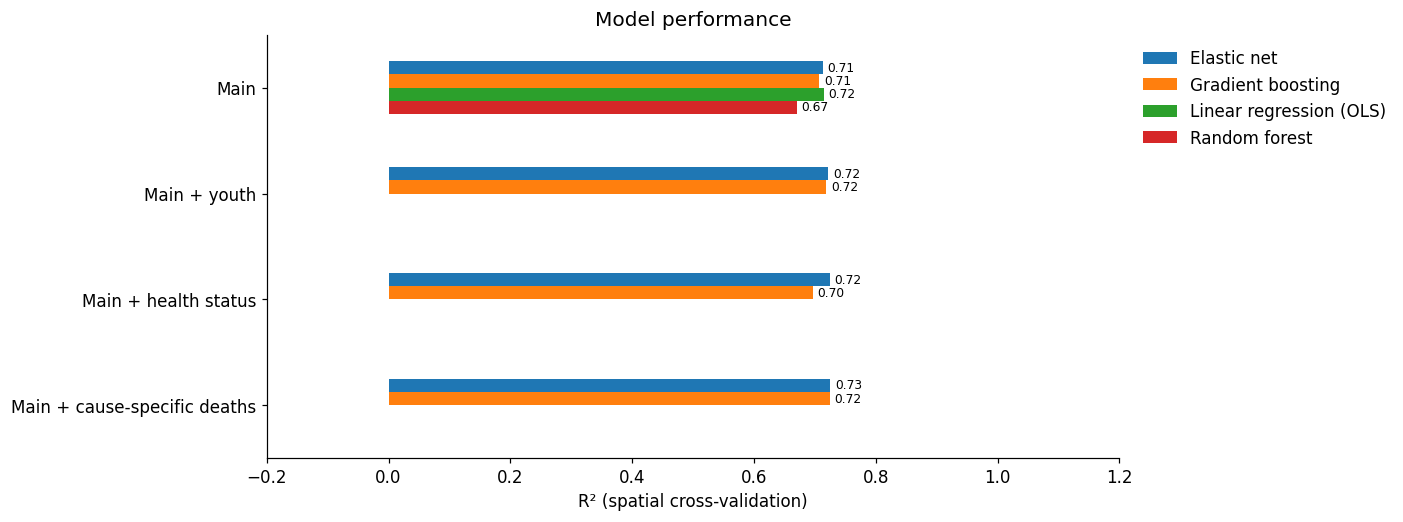

Baseline RMSE: 2.07 years
Gradient boosting, Main: random CV R² = 0.785, spatial CV R² = 0.708


In [5]:
spatial = results[(results.cv == "Spatial (by division)") & (results.model != "Baseline (mean)")]
p = spatial.pivot(index="features", columns="model", values="R2").loc[list(feature_sets)]

# A model that fails numerically can produce a hugely negative R²; clip so it does not
# flatten every other bar, and label the clipped ones with their real value.
FLOOR_BAR = -0.2
p_plot = p.clip(lower=FLOOR_BAR)
fig, ax = plt.subplots(figsize=(10, 5))
p_plot.plot.barh(ax=ax)
for cont, col in zip(ax.containers, p_plot.columns):
    ax.bar_label(cont, labels=["" if pd.isna(v) else
                               f"{v:.2f}" if v > FLOOR_BAR else f"{v:.2g} (off scale)"
                               for v in p[col]], padding=3, fontsize=8)
ax.set_xlabel("R² (spatial cross-validation)")
ax.set_ylabel("")
ax.set_xlim(FLOOR_BAR, 1.2)
ax.invert_yaxis()
ax.legend(title="", loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
ax.set_title("Model performance")
save(fig, "20_model_performance")
plt.show()

base = results.query("model == 'Baseline (mean)' and cv == 'Spatial (by division)'")
print(f"Baseline RMSE: {base.RMSE.iloc[0]:.2f} years")
rc = results.query("features == 'Main' and model == 'Gradient boosting'").set_index("cv").R2
print(f"Gradient boosting, Main: random CV R² = {rc['Random 5-fold']:.3f}, "
      f"spatial CV R² = {rc['Spatial (by division)']:.3f}")

## 4. Hold-out test: train on 80%, test on 20%

Cross-validation above reuses every county for both training and testing. A single
hold-out set is the simpler, more intuitive check: fit on 80% of counties, never look at
the other 20% until the end.

Two splits are reported, because they answer different questions:

- **Random 80/20** — the standard split. Optimistic here, because a held-out county's
  neighbours are probably in the training set and neighbouring counties resemble each other.
- **State-blocked 80/20** — whole states are held out, so the test counties have no
  neighbours in training. This is the honest estimate of how the model would do on a
  region it has never seen.

In [6]:
from sklearn.model_selection import GroupShuffleSplit, train_test_split

def evaluate(name, train_idx, test_idx, cols=features_main):
    Xtr, Xte = df[cols].iloc[train_idx], df[cols].iloc[test_idx]
    ytr, yte = y[train_idx], y[test_idx]
    imp = SimpleImputer(strategy="median").fit(Xtr)          # fit on TRAIN only
    Xtr_i = pd.DataFrame(imp.transform(Xtr), columns=cols, index=Xtr.index)
    Xte_i = pd.DataFrame(imp.transform(Xte), columns=cols, index=Xte.index)
    m = make_boost().fit(Xtr_i, ytr)
    pred = m.predict(Xte_i)
    return {"split": name, "n_train": len(train_idx), "n_test": len(test_idx),
            "R2": r2_score(yte, pred), "RMSE": mean_squared_error(yte, pred) ** 0.5,
            "MAE": mean_absolute_error(yte, pred),
            "within_1yr": 100 * (np.abs(yte - pred) < 1).mean(),
            "within_2yr": 100 * (np.abs(yte - pred) < 2).mean()}, m, imp, test_idx, pred

idx = np.arange(len(df))
tr_r, te_r = train_test_split(idx, test_size=0.2, random_state=SEED)
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
tr_s, te_s = next(gss.split(idx, groups=df["state"]))

res_r, model_r, imp_r, _, pred_r = evaluate("Random 80/20", tr_r, te_r)
res_s, model_s, imp_s, _, pred_s = evaluate("State-blocked 80/20", tr_s, te_s)

holdout = pd.DataFrame([res_r, res_s])
print(f"Baseline RMSE (predict the mean): {df[OUTCOME].std():.2f} years\n")
display(holdout.round(3))
print(f"States held out in the blocked split: "
      f"{sorted(df['state'].iloc[te_s].unique())}")

Baseline RMSE (predict the mean): 1.98 years



,split,n_train,n_test,R2,RMSE,MAE,within_1yr,within_2yr
0,Random 80/20,2463,616,0.778,0.947,0.68,78.896,96.591
1,State-blocked 80/20,2320,759,0.681,1.045,0.80,71.014,94.730


States held out in the blocked split: ['AZ', 'IA', 'ID', 'KY', 'MO', 'NH', 'NJ', 'NM', 'SC', 'TX', 'VT']


Saved C:\Users\14438\data\processed\figures\22_holdout_calibration.png


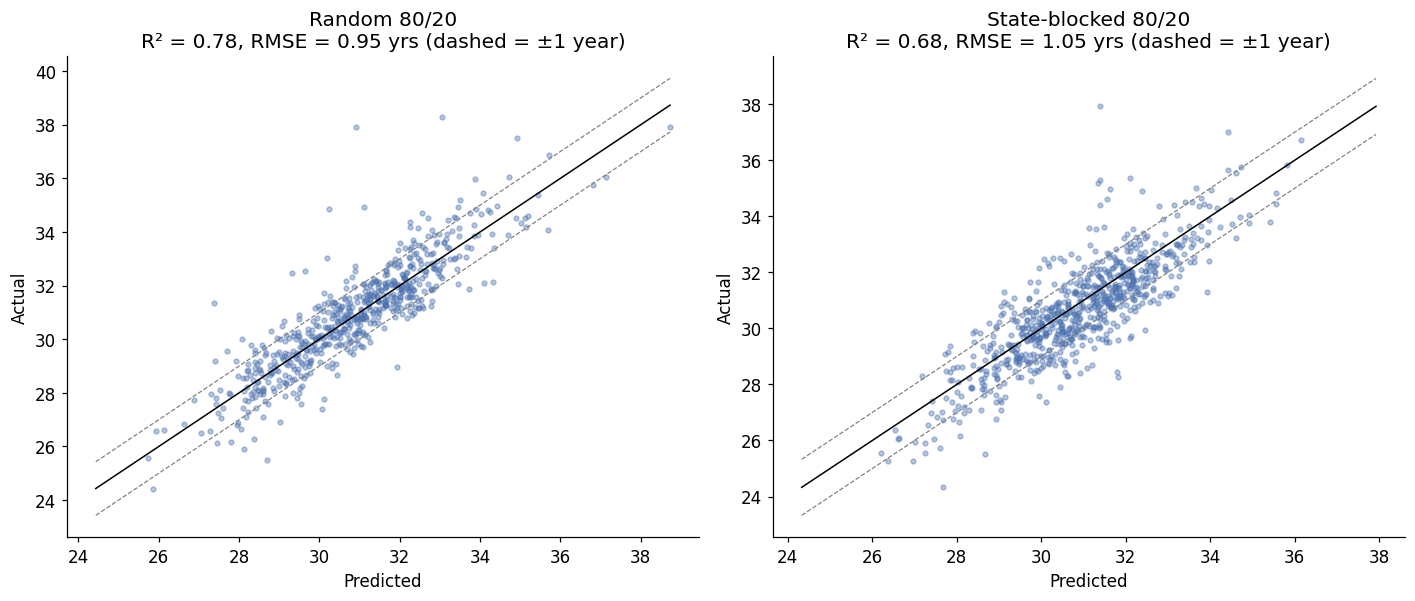

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.6))
for ax, (nm, te, pr) in zip(axes, [("Random 80/20", te_r, pred_r),
                                   ("State-blocked 80/20", te_s, pred_s)]):
    actual = y[te]
    ax.scatter(pr, actual, s=10, alpha=0.4, color="#4C72B0")
    lims = [min(pr.min(), actual.min()), max(pr.max(), actual.max())]
    ax.plot(lims, lims, color="black", lw=1)
    ax.plot(lims, [lims[0] + 1, lims[1] + 1], color="grey", lw=0.8, ls="--")
    ax.plot(lims, [lims[0] - 1, lims[1] - 1], color="grey", lw=0.8, ls="--")
    r2 = r2_score(actual, pr)
    rmse = mean_squared_error(actual, pr) ** 0.5
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    ax.set_title(f"{nm}\nR² = {r2:.2f}, RMSE = {rmse:.2f} yrs (dashed = ±1 year)")
fig.tight_layout()
save(fig, "22_holdout_calibration")
plt.show()

### Where is the model weakest?
Average error overall can hide poor performance on particular kinds of county. If error is
much larger for small or rural counties, predictions for those should carry a caveat —
including in the improvement scenarios below.

Saved C:\Users\14438\data\processed\figures\23_holdout_error_breakdown.png


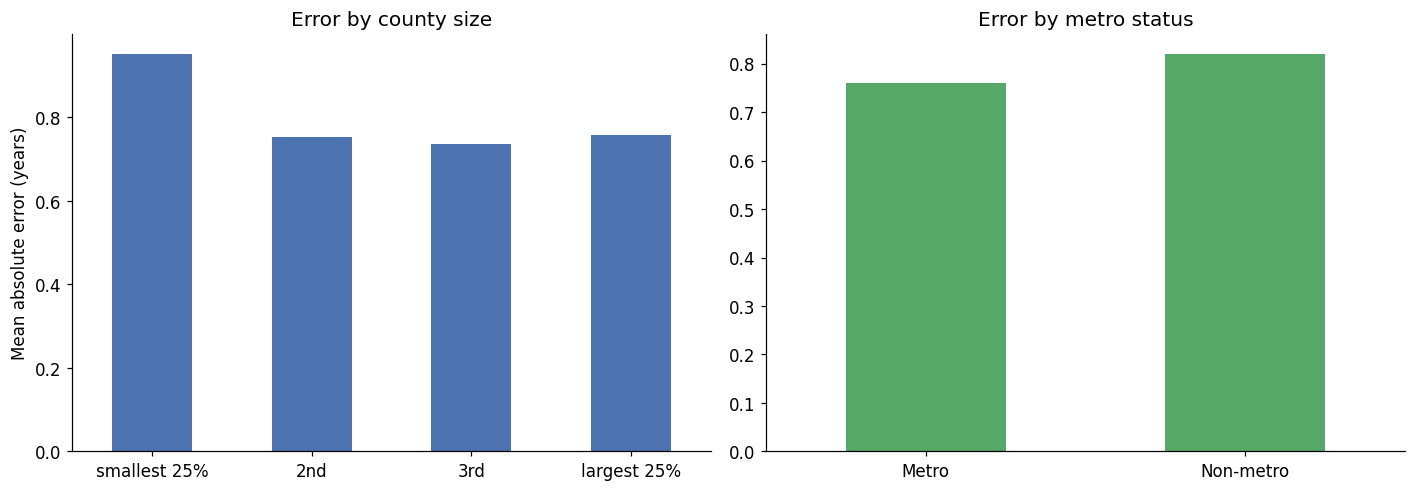

              count  mean  median
pop_group                        
smallest 25%    190  0.95    0.76
2nd             190  0.75    0.64
3rd             189  0.74    0.61
largest 25%     190  0.76    0.60

division
Middle Atlantic       0.96
Mountain              0.95
West South Central    0.88
East South Central    0.81
South Atlantic        0.79
New England           0.67
West North Central    0.64


In [8]:
te = te_s                                   # the harder, more honest split
err = pd.DataFrame({
    "abs_error": np.abs(y[te] - pred_s),
    "pop": df["acs_total_pop"].iloc[te].values,
    "rucc": df["rucc"].iloc[te].values,
    "division": df["census_division"].iloc[te].values,
})
err["pop_group"] = pd.qcut(err["pop"], 4,
                           labels=["smallest 25%", "2nd", "3rd", "largest 25%"])
err["place_type"] = np.where(err["rucc"] <= 3, "Metro", "Non-metro")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
err.groupby("pop_group", observed=True)["abs_error"].mean().plot.bar(
    ax=axes[0], color="#4C72B0", rot=0)
axes[0].set_ylabel("Mean absolute error (years)"); axes[0].set_xlabel("")
axes[0].set_title("Error by county size")
err.groupby("place_type")["abs_error"].mean().plot.bar(
    ax=axes[1], color="#55A868", rot=0)
axes[1].set_xlabel(""); axes[1].set_title("Error by metro status")
fig.tight_layout()
save(fig, "23_holdout_error_breakdown")
plt.show()

print(err.groupby("pop_group", observed=True)["abs_error"].agg(["count", "mean", "median"]).round(2))
print()
print(err.groupby("division")["abs_error"].mean().sort_values(ascending=False).round(2).to_string())

**What good hold-out performance does and does not license.**

It shows the model can predict a county's life expectancy from its characteristics,
including in states it never saw. That is real, and it is what makes the scenarios below
worth running at all.

It does **not** validate the scenario estimates. Those ask a different question — what
happens when one feature is moved while the rest are held fixed — and no amount of
predictive accuracy tests that. The honest claim stays: *counties similar to this one but
with that lower smoking rate have life expectancy about X years higher.*

### Is the difference between models real?

The headline numbers come from pooling every out-of-fold prediction into one R². That hides
how much the score moves from region to region. Scoring each held-out division separately
shows the spread, and whether the gap between models is bigger than the noise.

In [9]:
from sklearn.base import clone

fold_rows = []
gkf = GroupKFold(n_splits=df["census_division"].nunique())
for mdl in ["Linear regression (OLS)", "Elastic net", "Random forest", "Gradient boosting"]:
    for tr, te in gkf.split(df[features_main], y, groups=groups):
        m = MODELS[mdl]().fit(df[features_main].iloc[tr], y[tr])
        pr = m.predict(df[features_main].iloc[te])
        fold_rows.append({"model": mdl, "division": df["census_division"].iloc[te].iloc[0],
                          "n": len(te), "R2": r2_score(y[te], pr),
                          "RMSE": mean_squared_error(y[te], pr) ** 0.5})
folds = pd.DataFrame(fold_rows)

summary = folds.groupby("model")["R2"].agg(["mean", "median", "std", "min", "max"]).round(3)
summary["mean_RMSE"] = folds.groupby("model")["RMSE"].mean().round(3)
print("Per-division scores (each row = one held-out census division):")
display(summary)

# Paired comparison: same folds, so the difference per fold is the meaningful quantity
wide = folds.pivot(index="division", columns="model", values="R2")
diff = wide["Gradient boosting"] - wide["Elastic net"]
print(f"\nGradient boosting minus elastic net, per division:")
print(diff.round(3).sort_values().to_string())
print(f"\nmean {diff.mean():+.3f}, sd {diff.std():.3f}, "
      f"boosting wins in {int((diff > 0).sum())} of {len(diff)} divisions")
if abs(diff.mean()) < diff.std():
    print("-> the difference is smaller than the fold-to-fold variation: treat the two as tied")
else:
    print("-> the difference is larger than the fold-to-fold variation")

Per-division scores (each row = one held-out census division):


,mean,median,std,min,max,mean_RMSE
model,,,,,,
Elastic net,0.529,0.542,0.126,0.313,0.680,1.041
Gradient boosting,0.542,0.524,0.095,0.357,0.672,1.038
Linear regression (OLS),0.533,0.581,0.125,0.336,0.697,1.034
Random forest,0.467,0.492,0.147,0.219,0.705,1.116



Gradient boosting minus elastic net, per division:
division
South Atlantic       -0.036
Mountain             -0.035
Pacific              -0.017
West North Central   -0.007
East North Central    0.001
Middle Atlantic       0.010
West South Central    0.026
East South Central    0.044
New England           0.134

mean +0.013, sd 0.052, boosting wins in 5 of 9 divisions
-> the difference is smaller than the fold-to-fold variation: treat the two as tied


Saved C:\Users\14438\data\processed\figures\21_model_fold_spread.png


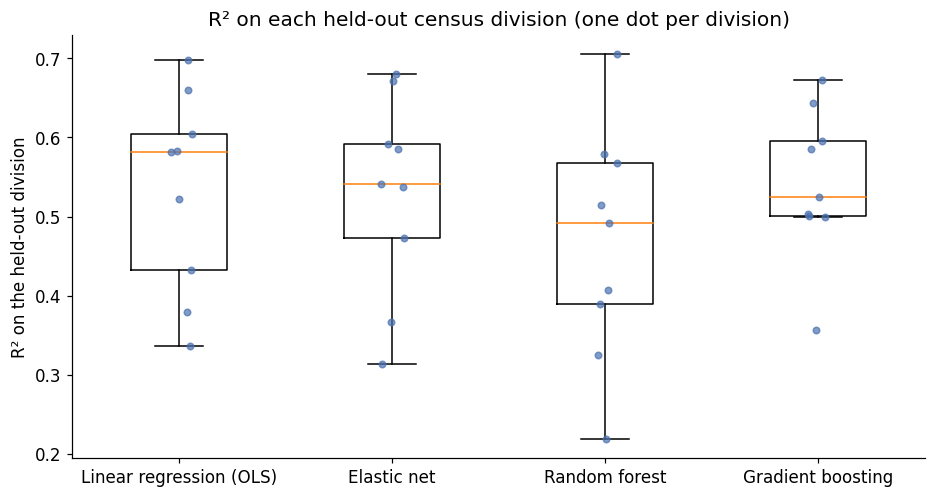

In [10]:
FLOOR = -0.5          # anything below this is a numerical failure, not a score
n_bad = int((folds["R2"] < FLOOR).sum())
if n_bad:
    print(f"{n_bad} model-fold combination(s) below R² = {FLOOR}, left off the chart:")
    print(folds[folds["R2"] < FLOOR][["model", "division", "R2"]].to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 5))
order = ["Linear regression (OLS)", "Elastic net", "Random forest", "Gradient boosting"]
# set_xticklabels rather than the tick_labels kwarg, which needs matplotlib >= 3.9
ax.boxplot([folds.loc[(folds.model == m) & (folds.R2 >= FLOOR), "R2"] for m in order],
           showfliers=False)
ax.set_xticks(range(1, len(order) + 1))
ax.set_xticklabels(order)
for k, m in enumerate(order, start=1):
    vals = folds.loc[(folds.model == m) & (folds.R2 >= FLOOR), "R2"]
    ax.scatter(np.full(len(vals), k) + np.random.uniform(-.06, .06, len(vals)),
               vals, s=18, alpha=0.7, color="#4C72B0", zorder=3)
ax.set_ylabel("R² on the held-out division")
ax.set_title("R² on each held-out census division (one dot per division)")
save(fig, "21_model_fold_spread")
plt.show()

### Elastic net coefficients

Because the two models score the same, the simpler one can carry the interpretation.
Features are standardised first, so each coefficient reads as: *years of life expectancy
associated with a one-standard-deviation increase in this feature, holding the rest fixed.*

This is the same caveat as everywhere else - association, not effect - but a coefficient is
far easier to state and to check than a SHAP value, and it does not depend on which
particular model was fitted.

In [11]:
en = MODELS["Elastic net"]().fit(df[features_main], y)
en_model = en.named_steps["elasticnetcv"]
# the imputer adds missing-indicator columns, so names must follow the pipeline
feat_names = list(en.named_steps["simpleimputer"].get_feature_names_out(features_main))
coefs = pd.Series(en_model.coef_, index=feat_names)
coefs = coefs[[c for c in features_main if c in coefs.index]]   # drop indicator columns

nonzero = coefs[coefs != 0].sort_values(key=abs, ascending=False)
print(f"alpha = {en_model.alpha_:.4f}, l1_ratio = {en_model.l1_ratio_}")
print(f"{len(nonzero)} of {len(coefs)} features kept (the rest shrunk to exactly zero)\n")

tab = pd.DataFrame({
    "years per +1 SD": nonzero.round(3),
    "group": ["modifiable" if c in MODIFIABLE else "structural" if c in STRUCTURAL else "fixed"
              for c in nonzero.index],
})
tab.index = [label(c) for c in nonzero.index]
display(tab.head(25))

dropped = coefs[coefs == 0]
if len(dropped):
    print(f"Shrunk to zero: {', '.join(label(c) for c in dropped.index)}")

# How much did the penalty actually move things?
ols = MODELS["Linear regression (OLS)"]().fit(df[features_main], y)
ols_names = list(ols.named_steps["variancethreshold"]
                 .get_feature_names_out(features_main))
ols_coefs = pd.Series(ols.named_steps["linearregression"].coef_, index=ols_names)
ols_coefs = ols_coefs[[c for c in features_main if c in ols_coefs.index]]

side = pd.DataFrame({"OLS": ols_coefs, "elastic net": coefs})
side["shrinkage"] = (side["OLS"] - side["elastic net"]).abs()
side.index = [label(c) for c in side.index]
print(f"\nLargest OLS coefficient: {side.OLS.abs().max():.3f} years/SD; "
      f"largest after the penalty: {side['elastic net'].abs().max():.3f}")
print("Where the penalty changed the coefficient most:")
display(side.reindex(side["shrinkage"].sort_values(ascending=False).index).head(10).round(3))

alpha = 0.0545, l1_ratio = 0.1
46 of 51 features kept (the rest shrunk to exactly zero)



,years per +1 SD,group
% age 25+ with bachelor's degree or higher,0.474,structural
% 65 and Older,0.414,fixed
% Not Proficient in English,0.352,fixed
Median household income (2019 $),0.273,structural
% Hispanic or Latino,0.258,fixed
Economic connectedness: share of high-income,0.235,structural
Standardized Medicare spending per FFS benefi,-0.209,structural
Adult Smoking,-0.200,modifiable
Mammography Screening,0.178,modifiable
% non-Hispanic Black,0.150,fixed


Shrunk to zero: Access to Exercise Opportunities, Uninsured Adults, Gender Pay Gap, % of FFS beneficiaries also eligible for Medi, Log population

Largest OLS coefficient: 0.573 years/SD; largest after the penalty: 0.474
Where the penalty changed the coefficient most:


,OLS,elastic net,shrinkage
% non-Hispanic Black,0.299,0.150,0.149
Adult Smoking,-0.065,-0.200,0.136
% age 25+ with HS diploma/GED or higher,0.265,0.146,0.119
% Rural,0.183,0.066,0.117
% Hispanic or Latino,0.370,0.258,0.112
% 65 and Older,0.514,0.414,0.100
% age 25+ with bachelor's degree or higher,0.573,0.474,0.100
Log population,0.089,0.000,0.089
Median household income (2019 $),0.349,0.273,0.076
Long Commute - Driving Alone,-0.094,-0.022,0.071


Saved C:\Users\14438\data\processed\figures\29_elasticnet_coefficients.png


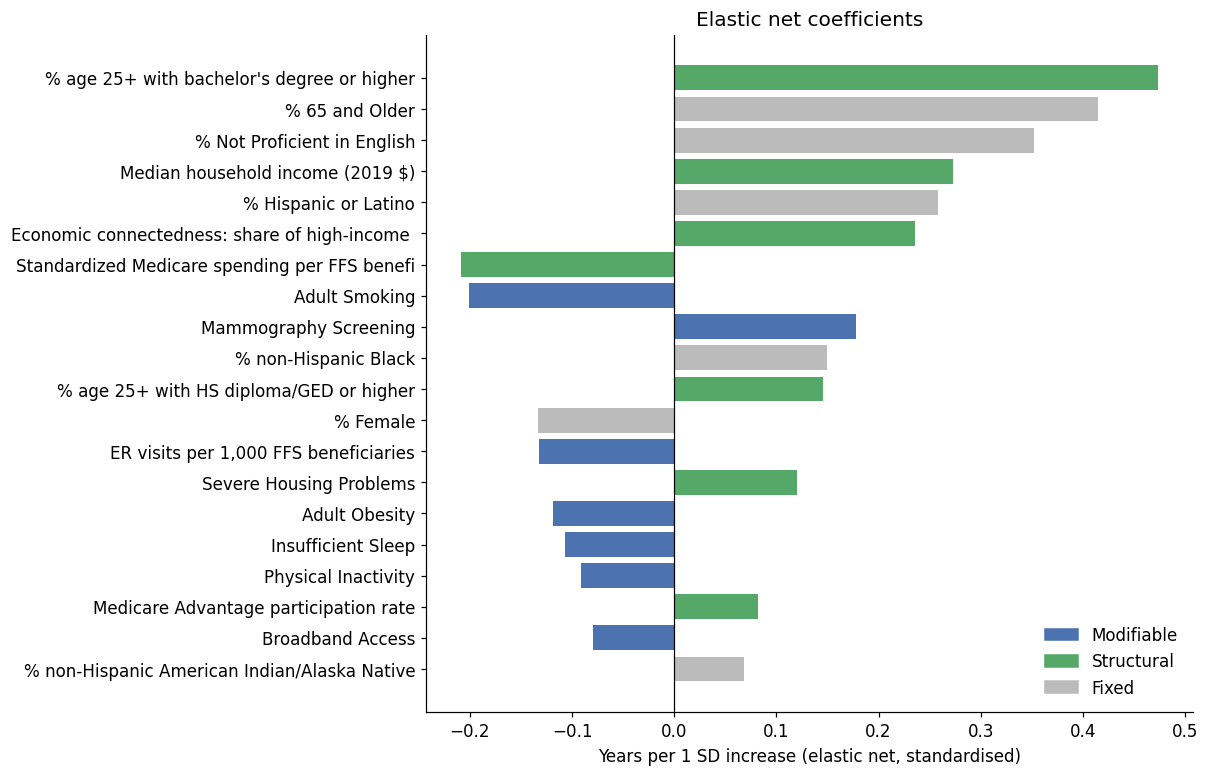

In [12]:
top = nonzero.head(20)[::-1]
colors = ["#4C72B0" if c in MODIFIABLE else "#55A868" if c in STRUCTURAL else "#BBBBBB"
          for c in top.index]
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh([label(c) for c in top.index], top.values, color=colors)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Years per 1 SD increase (elastic net, standardised)")
ax.set_title("Elastic net coefficients")
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in ["#4C72B0", "#55A868", "#BBBBBB"]],
          ["Modifiable", "Structural", "Fixed"], loc="lower right", frameon=False)
save(fig, "29_elasticnet_coefficients")
plt.show()

## 5. Final model

Fitted on all counties using the **Main** feature set — upstream factors only, no
health-status or death-based measures — because the point is to explain conditions, not to
predict mortality from mortality. Out-of-fold predictions come from the spatial CV, so
every county's prediction comes from a model that never saw its region.

Out-of-fold (spatial) R² = 0.708, RMSE = 1.07 years
Saved C:\Users\14438\data\processed\figures\24_pred_vs_actual.png


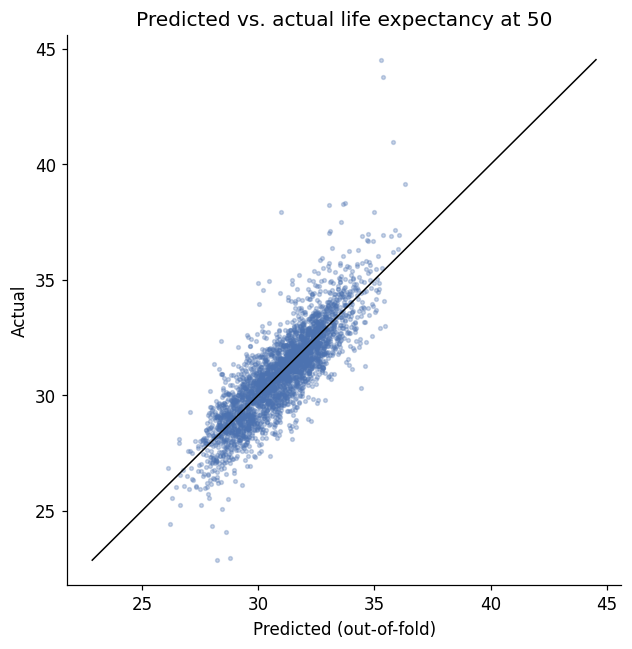

Living longer than predicted (pop 50k+):


,place,le50_both,pred,residual,acs_total_pop
250,"Eagle County, CO",41.0,35.799999,5.1,54681.0
312,"Collier County, FL",38.3,33.700001,4.6,371453.0
98,"Pinal County, AZ",35.2,31.700001,3.5,432793.0
328,"Highlands County, FL",32.6,29.500000,3.1,103437.0
101,"Yuma County, AZ",35.0,32.200001,2.8,230261.0
2361,"Lincoln County, SD",35.7,33.099998,2.7,56826.0
336,"Lee County, FL",35.6,33.000000,2.6,737468.0
1780,"San Juan County, NM",32.1,29.600000,2.5,126515.0


Living shorter than predicted (pop 50k+):


,place,le50_both,pred,residual,acs_total_pop
1424,"Madison County, MS",28.9,32.299999,-3.4,104562.0
301,"District of Columbia, DC",31.3,34.599998,-3.3,692683.0
63,"Walker County, AL",26.3,29.000000,-2.8,64110.0
1726,"Carson City, NV",28.9,31.600000,-2.7,54773.0
1741,"Cape May County, NJ",31.3,33.900002,-2.6,93086.0
2548,"Ector County, TX",28.7,31.299999,-2.6,160579.0
2663,"Potter County, TX",27.6,30.100000,-2.5,119674.0
2656,"Orange County, TX",28.3,30.700001,-2.4,84069.0


In [13]:
X = df[features_main]
imputer = SimpleImputer(strategy="median").fit(X)
X_imp = pd.DataFrame(imputer.transform(X), columns=features_main, index=df.index)

final_model = make_boost().fit(X_imp, y)

df["pred"] = oof[("Main", "Gradient boosting", "Spatial (by division)")]
df["residual"] = df[OUTCOME] - df["pred"]
print(f"Out-of-fold (spatial) R² = {r2_score(y, df['pred']):.3f}, "
      f"RMSE = {mean_squared_error(y, df['pred'])**0.5:.2f} years")

fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.scatter(df["pred"], df[OUTCOME], s=6, alpha=0.3, color="#4C72B0")
lims = [min(df.pred.min(), df[OUTCOME].min()), max(df.pred.max(), df[OUTCOME].max())]
ax.plot(lims, lims, color="black", lw=1)
ax.set_xlabel("Predicted (out-of-fold)"); ax.set_ylabel("Actual")
ax.set_title("Predicted vs. actual life expectancy at 50")
save(fig, "24_pred_vs_actual")
plt.show()

cols = ["place", OUTCOME, "pred", "residual", "acs_total_pop"]
big = df[df.acs_total_pop >= 50_000]
print("Living longer than predicted (pop 50k+):")
display(big.nlargest(8, "residual")[cols].round(1))
print("Living shorter than predicted (pop 50k+):")
display(big.nsmallest(8, "residual")[cols].round(1))

## 6. What drives the model: SHAP

SHAP splits each prediction into per-feature contributions that sum to the prediction.
Correlated features share credit, so read this as "how the model uses these variables",
not as isolated effects.

shap.TreeExplainer failed (ValueError: could not convert string to float: '[5E-1]')
SHAP values via XGBoost's own pred_contribs - identical values
Saved C:\Users\14438\data\processed\figures\25_shap_importance.png


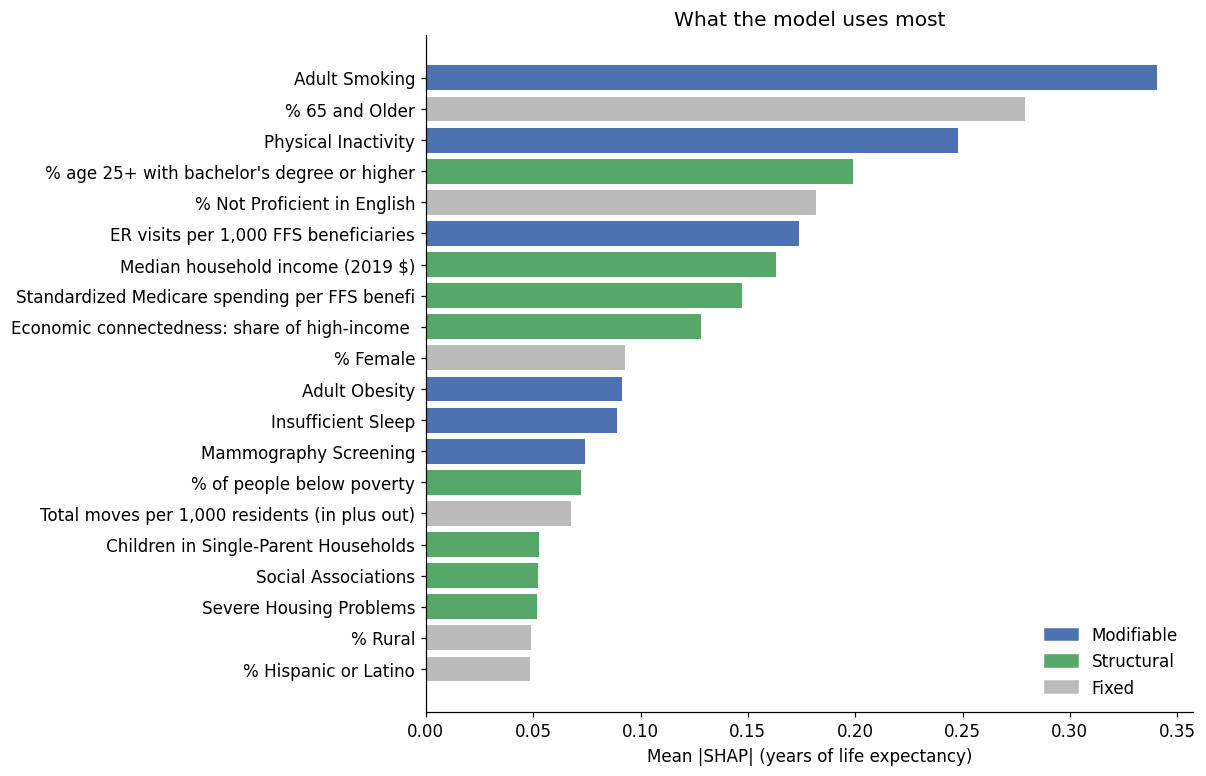

,mean |SHAP| (years)
Adult Smoking,0.340
% 65 and Older,0.279
Physical Inactivity,0.248
% age 25+ with bachelor's degree or higher,0.199
% Not Proficient in English,0.182
"ER visits per 1,000 FFS beneficiaries",0.174
Median household income (2019 $),0.163
Standardized Medicare spending per FFS benefi,0.147
Economic connectedness: share of high-income,0.128
% Female,0.093


In [14]:
# SHAP values, by whichever route works. XGBoost can compute them itself, which
# sidesteps version mismatches between xgboost and the shap package.
sv, HAS_SHAP = None, False
try:
    import shap
    sv = shap.TreeExplainer(final_model).shap_values(X_imp)
    HAS_SHAP = True
    print("SHAP values via the shap package")
except Exception as e:
    print(f"shap.TreeExplainer failed ({type(e).__name__}: {e})")
    try:
        import xgboost as xgb
        booster = final_model.get_booster()
        contribs = booster.predict(xgb.DMatrix(X_imp), pred_contribs=True)
        sv = contribs[:, :-1]            # last column is the bias term
        HAS_SHAP = True
        print("SHAP values via XGBoost's own pred_contribs - identical values")
    except Exception as e2:
        print(f"XGBoost fallback also failed ({type(e2).__name__}: {e2})")
        print("Continuing without SHAP; sections 6 and 10 will skip the explanations.")

if HAS_SHAP:
    shap_df = pd.DataFrame(sv, columns=features_main, index=df.index)
    imp = shap_df.abs().mean().sort_values(ascending=False)
    top = imp.head(20)[::-1]
    group_color = {**{c: "#4C72B0" for c in MODIFIABLE},
                   **{c: "#55A868" for c in STRUCTURAL},
                   **{c: "#BBBBBB" for c in FIXED}}
    fig, ax = plt.subplots(figsize=(9, 8))
    ax.barh([label(c) for c in top.index], top.values,
            color=[group_color[c] for c in top.index])
    ax.set_xlabel("Mean |SHAP| (years of life expectancy)")
    ax.set_title("What the model uses most")
    handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in ["#4C72B0", "#55A868", "#BBBBBB"]]
    ax.legend(handles, ["Modifiable", "Structural", "Fixed"],
              loc="lower right", frameon=False)
    save(fig, "25_shap_importance")
    plt.show()
    display(imp.head(15).round(3).rename(index=label).to_frame("mean |SHAP| (years)"))

Saved C:\Users\14438\data\processed\figures\26_shap_beeswarm.png


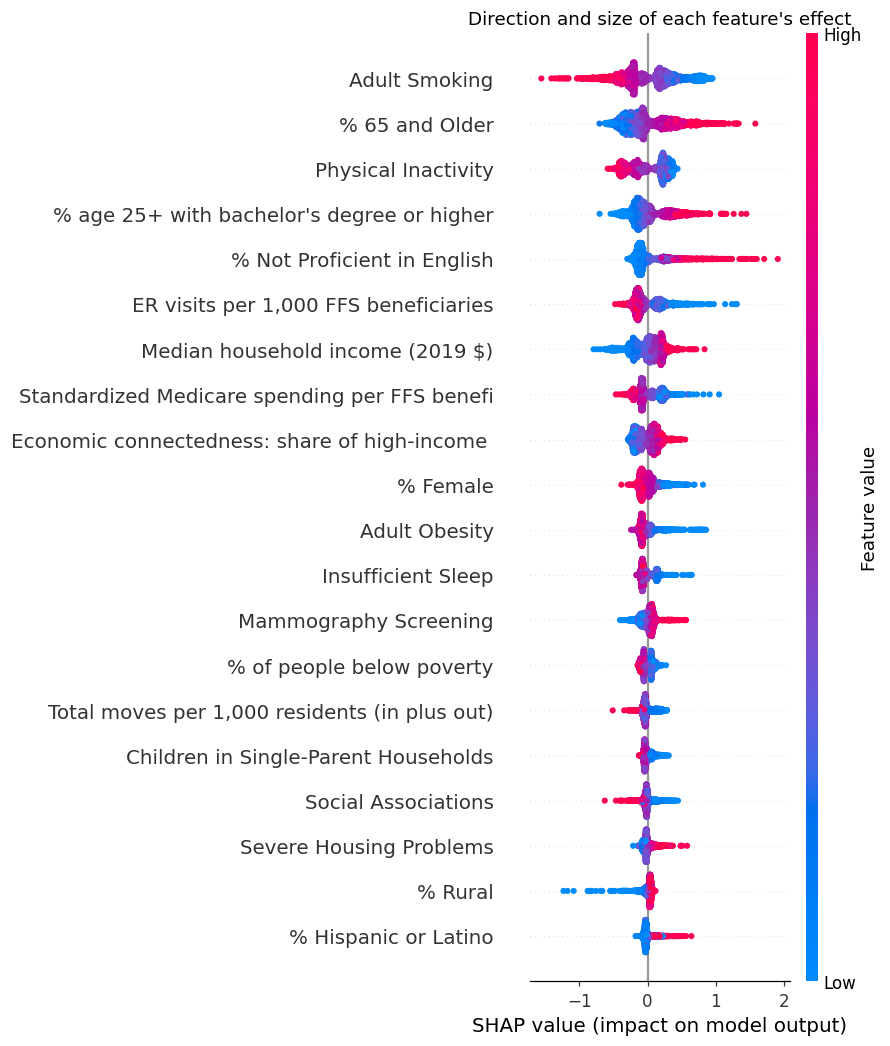

In [15]:
if HAS_SHAP and "shap" in dir():
    fig = plt.figure()
    shap.summary_plot(sv, X_imp, feature_names=[label(c) for c in features_main],
                      max_display=20, show=False)
    plt.title("Direction and size of each feature's effect", fontsize=12)
    save(plt.gcf(), "26_shap_beeswarm")
    plt.show()

### Do the two models agree on what matters?

If a regularised linear model and a gradient-boosted ensemble rank the drivers the same
way, the ranking is a property of the data rather than of one modelling choice. Where they
disagree is worth a look: it usually means a non-linear relationship that the linear model
is flattening.

Rank agreement between SHAP and elastic net: Spearman rho = 0.73
Saved C:\Users\14438\data\processed\figures\30_rank_agreement.png


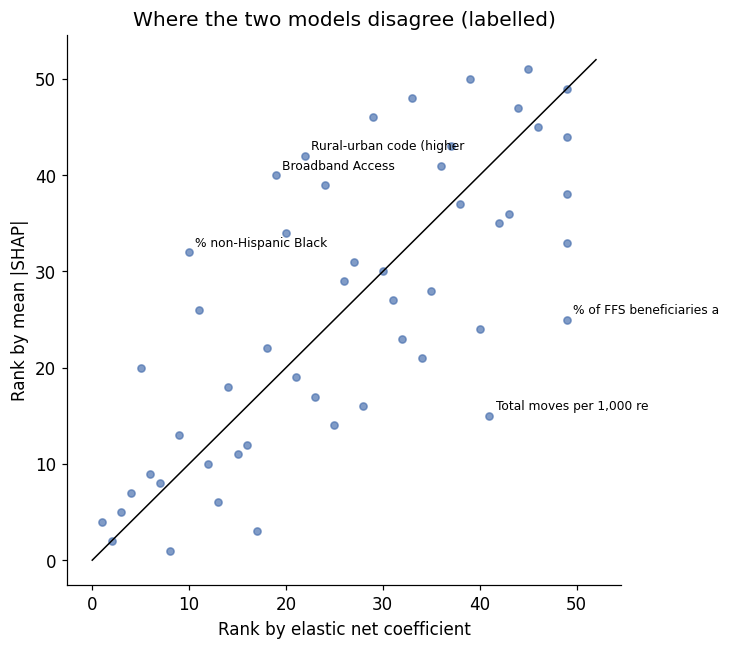

,SHAP rank,coef rank,gap
feature,,,
"Total moves per 1,000 residents (in plus out)",15.0,41.0,26.0
% of FFS beneficiaries also eligible for Medi,25.0,49.0,24.0
% non-Hispanic Black,32.0,10.0,22.0
Broadband Access,40.0,19.0,21.0
Rural-urban code (higher = more rural),42.0,22.0,20.0
Mental Health Providers (per 100k),46.0,29.0,17.0
Excessive Drinking,24.0,40.0,16.0
Log population,33.0,49.0,16.0


In [16]:
if HAS_SHAP:
    shap_rank = pd.Series(np.abs(sv).mean(axis=0), index=features_main).rank(ascending=False)
    coef_rank = coefs.abs().rank(ascending=False)
    cmp = pd.DataFrame({"SHAP rank": shap_rank, "coef rank": coef_rank}).dropna()
    cmp["gap"] = (cmp["SHAP rank"] - cmp["coef rank"]).abs()
    rho = cmp["SHAP rank"].corr(cmp["coef rank"], method="spearman")
    print(f"Rank agreement between SHAP and elastic net: Spearman rho = {rho:.2f}")

    fig, ax = plt.subplots(figsize=(6.5, 6.5))
    ax.scatter(cmp["coef rank"], cmp["SHAP rank"], s=22, alpha=0.7, color="#4C72B0")
    lim = [0, len(cmp) + 1]
    ax.plot(lim, lim, color="black", lw=1)
    for c in cmp.nlargest(5, "gap").index:
        ax.annotate(label(c)[:24], (cmp.loc[c, "coef rank"], cmp.loc[c, "SHAP rank"]),
                    fontsize=8, xytext=(4, 4), textcoords="offset points")
    ax.set_xlabel("Rank by elastic net coefficient")
    ax.set_ylabel("Rank by mean |SHAP|")
    ax.set_title("Where the two models disagree (labelled)")
    save(fig, "30_rank_agreement")
    plt.show()
    display(cmp.nlargest(8, "gap").assign(feature=[label(c) for c in cmp.nlargest(8, "gap").index])
            .set_index("feature").round(1))

## 7. Peer counties

A county's realistic comparison is not the national average — it is counties with similar
size, rurality, age structure, race composition and migration. Peers are the nearest
counties in that fixed-characteristic space, which is also the honest way to set a target:
something counties like this one already achieve.

In [17]:
from sklearn.neighbors import NearestNeighbors

N_PEERS = 25
F = df[FIXED].copy()
F = (F - F.mean()) / F.std(ddof=0)
F = F.fillna(0)
nn = NearestNeighbors(n_neighbors=N_PEERS + 1).fit(F.values)
_, idx = nn.kneighbors(F.values)
peer_idx = idx[:, 1:]            # drop self

def peers(i):
    return df.iloc[peer_idx[i]]

def row_for(fips_or_name):
    m = df[(df.fips == str(fips_or_name)) |
           df.place.str.lower().str.startswith(str(fips_or_name).lower())]
    if m.empty:
        raise ValueError(f"No county matching {fips_or_name!r}. Try a 5-digit FIPS code "
                         f'or a name like "Baltimore". Example: {df.place.iloc[0]!r}')
    return m.index[0]

EXAMPLE = "01001" if "01001" in set(df.fips) else df.fips.iloc[0]   # Autauga County, AL
i = row_for(EXAMPLE)
p = peers(i)
print(f"{df.place[i]} - life expectancy at 50: {df[OUTCOME][i]:.1f} years "
      f"(predicted {df.pred[i]:.1f})")
print(f"Peer group of {len(p)}: mean {p[OUTCOME].mean():.1f}, "
      f"best {p[OUTCOME].max():.1f} ({p.loc[p[OUTCOME].idxmax(), 'place']})")
display(p[["place", OUTCOME, "acs_total_pop", "rucc"]].sort_values(OUTCOME, ascending=False)
        .head(8).round(1))

Autauga County, AL - life expectancy at 50: 30.2 years (predicted 30.1)
Peer group of 25: mean 30.6, best 32.7 (Calvert County, MD)


,place,le50_both,acs_total_pop,rucc
1176,"Calvert County, MD",32.7,91511.0,1.0
2812,"Hanover County, VA",32.3,105537.0,1.0
1416,"Lamar County, MS",32.2,61969.0,3.0
1440,"Rankin County, MS",32.1,152677.0,2.0
1480,"Cass County, MO",31.9,103597.0,1.0
2816,"Isle of Wight County, VA",31.9,36627.0,1.0
2131,"Logan County, OK",31.8,46683.0,1.0
2947,"Jefferson County, WV",31.6,56506.0,1.0


## 8. Where does a county trail its peers?

For each modifiable feature, compares the county with the **top quartile of its peers** —
the value a quarter of similar counties already reach. A gap here is a realistic target,
not an aspiration drawn from the other end of the country.

In [18]:
# Which direction is "better" for each feature? Learned from the data, not assumed.
corr_sign = {c: np.sign(df[c].corr(df[OUTCOME], method="spearman")) for c in MODIFIABLE}

def gaps(i, feats=None):
    feats = feats or MODIFIABLE
    p = peers(i)
    out = []
    for c in feats:
        v = df[c][i]
        if pd.isna(v):
            continue
        s = corr_sign[c]
        target = p[c].quantile(0.75 if s > 0 else 0.25)   # better = higher or lower
        if pd.isna(target):
            continue
        behind = (target - v) * s                          # >0 means the county trails
        out.append({"feature": c, "label": label(c), "county": v,
                    "peer_target": target, "gap": target - v,
                    "behind": behind > 0,
                    "pct_of_peers_better": 100 * ((p[c] - v) * s > 0).mean()})
    return pd.DataFrame(out).sort_values("pct_of_peers_better", ascending=False)

g = gaps(i)
n_behind, n_total = int(g.behind.sum()), len(g)
print(f"{df.place[i]}: trails its peers on {n_behind} of {n_total} modifiable factors")
print(f"(the target is each peer group's top quartile, so a typical county trails on "
      f"about {0.75 * n_total:.0f} of {n_total} by construction - see the note below)")
display(g[g.behind][["label", "county", "peer_target", "pct_of_peers_better"]].round(2).head(10))

# How many does a county trail on, nationally? Puts any one county in context.
_counts = [int(gaps(k).behind.sum()) for k in df.sample(min(300, len(df)), random_state=SEED).index]
print(f"\nAcross a 300-county sample: median {int(np.median(_counts))} factors behind, "
      f"range {min(_counts)}-{max(_counts)} of {n_total}")

Autauga County, AL: trails its peers on 18 of 18 modifiable factors
(the target is each peer group's top quartile, so a typical county trails on about 14 of 18 by construction - see the note below)


,label,county,peer_target,pct_of_peers_better
11,Preventable Hospital Stays,4372.00,2863.00,100.0
9,Mental Health Providers (per 100k),35.54,176.28,92.0
13,Flu Vaccinations,0.42,0.53,92.0
5,Food Environment Index,6.60,8.20,92.0
6,Access to Exercise Opportunities,0.56,0.81,80.0
10,Dentists (per 100k),32.15,49.67,80.0
17,"ER visits per 1,000 FFS beneficiaries",757.44,656.47,76.0
16,30-day hospital readmission %,0.18,0.17,64.0
1,Adult Obesity,0.37,0.35,60.0
4,Insufficient Sleep,0.38,0.33,60.0



Across a 300-county sample: median 14 factors behind, range 0-18 of 18


## 9. Improvement scenarios

For each factor where the county trails, the feature is moved to the peer target, the model
is re-run, and the change in predicted years is recorded. Everything else is held fixed.

Two guardrails: each target is a value peer counties actually reach, so no single change
asks the model about territory it has not seen; and the combined scenario is computed by
changing all the factors at once rather than adding up the individual gains, which would
double-count overlapping effects.

One caveat on the combined figure. Each target is individually realistic, but hitting the
top quartile on *every* factor at once is a bundle no single peer county achieves, so the
combined number is best read as an upper bound on what matching peers could look like -
not as an achievable programme.

Autauga County, AL - model baseline 29.76 years
Matching peer targets on all 18 factors at once: +0.65 years
(less than the sum of the individual gains below, because the factors overlap)



,feature,label,from,to,years_gained
11,chr_physical_inactivity,Physical Inactivity,0.26,0.24,0.25
3,chr_food_environment_index,Food Environment Index,6.60,8.20,0.18
17,chr_adult_smoking,Adult Smoking,0.18,0.17,0.14
1,chr_mental_health_providers,Mental Health Providers (per 100k),35.54,176.28,0.08
10,chr_excessive_drinking,Excessive Drinking,0.17,0.18,0.04
8,chr_adult_obesity,Adult Obesity,0.37,0.35,0.02
2,chr_flu_vaccinations,Flu Vaccinations,0.42,0.53,0.02
14,chr_uninsured_adults,Uninsured Adults,0.13,0.09,0.01
13,chr_broadband_access,Broadband Access,0.85,0.88,0.01
6,cms_er_visits_per_1000,"ER visits per 1,000 FFS beneficiaries",757.44,656.47,0.00


Saved C:\Users\14438\data\processed\figures\27_scenarios_example.png


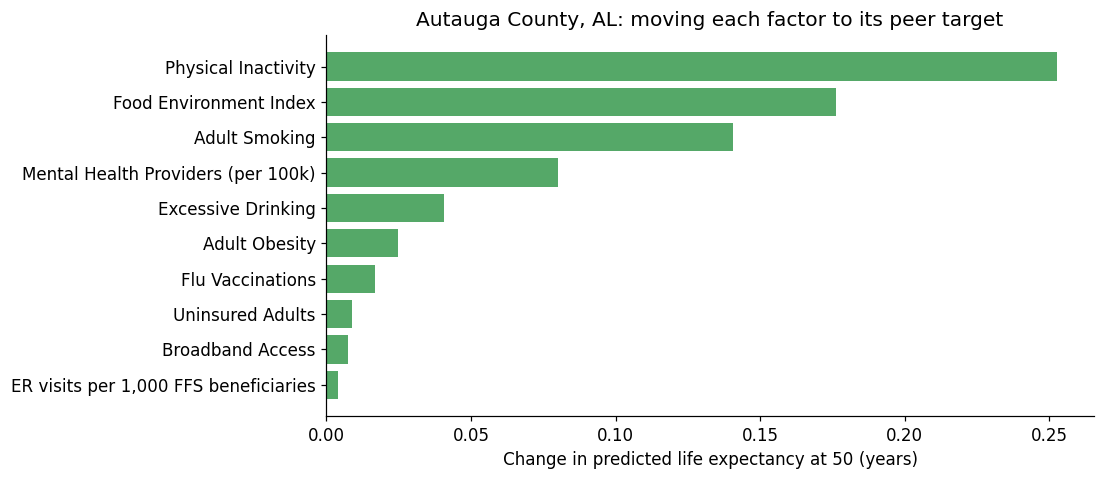

In [19]:
def scenarios(i, feats=None, model=None, top=10):
    """All of a county's scenarios are predicted in ONE batch - a per-row predict
    call for every feature would be tens of thousands of calls across all counties."""
    model = model or final_model
    g = gaps(i, feats)
    g = g[g.behind]
    base_row = X_imp.iloc[i].values

    # row 0 = unchanged, rows 1..n = one feature moved, last row = all moved
    n = len(g)
    M = np.tile(base_row, (n + 2, 1))
    pos = {c: k for k, c in enumerate(features_main)}
    for j, r in enumerate(g.itertuples()):
        M[j + 1, pos[r.feature]] = r.peer_target
        M[-1, pos[r.feature]] = r.peer_target
    preds = model.predict(pd.DataFrame(M, columns=features_main))

    base_pred, combined = float(preds[0]), float(preds[-1] - preds[0])
    s = pd.DataFrame({"feature": g.feature.values, "label": g.label.values,
                      "from": g.county.values, "to": g.peer_target.values,
                      "years_gained": preds[1:n + 1] - preds[0]})
    s = s.sort_values("years_gained", ascending=False)
    return s.head(top), base_pred, combined, n

s, base_pred, combined, n_gaps = scenarios(i)
print(f"{df.place[i]} - model baseline {base_pred:.2f} years")
print(f"Matching peer targets on all {n_gaps} factors at once: {combined:+.2f} years")
print("(less than the sum of the individual gains below, because the factors overlap)\n")
display(s.round(2))

fig, ax = plt.subplots(figsize=(9, max(3, 0.45 * len(s))))
sub = s.iloc[::-1]
ax.barh(sub["label"], sub["years_gained"], color="#55A868")
ax.set_xlabel("Change in predicted life expectancy at 50 (years)")
ax.set_title(f"{df.place[i]}: moving each factor to its peer target")
save(fig, "27_scenarios_example")
plt.show()

## 10. One-page county report

Everything above for a single county. Change the argument to look at any county by FIPS
code or by name.

In [20]:
def county_report(key, n_show=8):
    i = row_for(key)
    p = peers(i)
    print("=" * 72)
    print(f"{df.place[i]}   (FIPS {df.fips[i]}, population {df.acs_total_pop[i]:,.0f})")
    print("=" * 72)
    print(f"Life expectancy at 50 : {df[OUTCOME][i]:.1f} years "
          f"(national county median {df[OUTCOME].median():.1f})")
    print(f"National rank         : {int(df[OUTCOME].rank(ascending=False)[i])} of {len(df)}")
    print(f"Model prediction      : {df.pred[i]:.1f}  (residual {df.residual[i]:+.1f})")
    print(f"Peer group            : mean {p[OUTCOME].mean():.1f}, best {p[OUTCOME].max():.1f}")

    if HAS_SHAP:
        sh = shap_df.iloc[i].sort_values(key=abs, ascending=False).head(n_show)
        print("\nWhat most shapes this county's prediction (SHAP, years):")
        for c, v in sh.items():
            tag = "modifiable" if c in MODIFIABLE else ("structural" if c in STRUCTURAL else "fixed")
            print(f"   {v:+.2f}  {label(c):45} [{tag}]")

    s, base_pred, combined, n_gaps = scenarios(i, top=n_show)
    if len(s):
        print(f"\nIf it matched its peers' top quartile ({n_gaps} factors): {combined:+.2f} years")
        print("Largest single associations:")
        for r in s.itertuples():
            print(f"   {r.years_gained:+.2f}  {r.label:45} "
                  f"{r._3:.1f} -> {r.to:.1f}")
    else:
        print("\nThis county already matches or beats its peers on every modifiable factor.")
    print("\nAssociational, not causal - see the note at the top of this notebook.")

county_report(EXAMPLE)

Autauga County, AL   (FIPS 01001, population 55,380)
Life expectancy at 50 : 30.2 years (national county median 30.9)
National rank         : 2008 of 3079
Model prediction      : 30.1  (residual +0.1)
Peer group            : mean 30.6, best 32.7

What most shapes this county's prediction (SHAP, years):
   -0.40  % 65 and Older                                [fixed]
   +0.26  Adult Smoking                                 [modifiable]
   -0.21  Physical Inactivity                           [modifiable]
   +0.19  Median household income (2019 $)              [structural]
   -0.17  % Not Proficient in English                   [fixed]
   -0.14  Economic connectedness: share of high-income  [structural]
   +0.12  % age 25+ with bachelor's degree or higher    [structural]
   -0.11  ER visits per 1,000 FFS beneficiaries         [modifiable]

If it matched its peers' top quartile (18 factors): +0.65 years
Largest single associations:
   +0.25  Physical Inactivity                           0.3 

In [21]:
# Try a county that does much worse than predicted
county_report(df.loc[df[df.acs_total_pop > 100_000].residual.idxmin(), "fips"])

Madison County, MS   (FIPS 28089, population 104,562)
Life expectancy at 50 : 28.9 years (national county median 30.9)
National rank         : 2611 of 3079
Model prediction      : 32.3  (residual -3.4)
Peer group            : mean 30.1, best 32.1

What most shapes this county's prediction (SHAP, years):
   +0.77  Adult Smoking                                 [modifiable]
   -0.50  % 65 and Older                                [fixed]
   +0.40  % age 25+ with bachelor's degree or higher    [structural]
   +0.32  Physical Inactivity                           [modifiable]
   -0.25  Economic connectedness: share of high-income  [structural]
   -0.20  Standardized Medicare spending per FFS benefi [structural]
   -0.18  % Hispanic or Latino                          [fixed]
   -0.17  % Not Proficient in English                   [fixed]

If it matched its peers' top quartile (4 factors): +0.38 years
Largest single associations:
   +0.27  30-day hospital readmission %                 0.2 -> 0.

## 10b. The lowest-performing counties

Applies the peer-target scenarios to the counties with the shortest life expectancy at 50,
then asks which factors come up most often across them. This is the closest thing the
project offers to a policy read: not what any single county must do, but where the gap
between struggling counties and their own peers is widest.

In [22]:
N_WORST = 100
worst = df.nsmallest(N_WORST, OUTCOME)

rows = []
for i in worst.index:
    s, base_pred, combined, n_gaps = scenarios(i, top=99)
    for r in s.itertuples():
        rows.append({"fips": df.fips[i], "place": df.place[i], "feature": r.feature,
                     "label": r.label, "years_gained": r.years_gained,
                     "combined": combined, "le50": df[OUTCOME][i]})
w = pd.DataFrame(rows)

per_county = w.groupby("fips").agg(place=("place", "first"), le50=("le50", "first"),
                                   combined=("combined", "first"), n_factors=("feature", "size"))
print(f"The {N_WORST} shortest-lived counties: mean life expectancy at 50 = "
      f"{worst[OUTCOME].mean():.1f} years vs. {df[OUTCOME].median():.1f} nationally")
print(f"Matching their own peers' top quartile is associated with "
      f"{per_county.combined.median():+.2f} years (median), "
      f"range {per_county.combined.min():+.2f} to {per_county.combined.max():+.2f}")
print(f"That closes about "
      f"{100 * per_county.combined.median() / (df[OUTCOME].median() - worst[OUTCOME].mean()):.0f}% "
      f"of their gap to the national median.\n")
display(per_county.sort_values("combined", ascending=False).head(10).round(2))

The 100 shortest-lived counties: mean life expectancy at 50 = 26.6 years vs. 30.9 nationally
Matching their own peers' top quartile is associated with +1.54 years (median), range +0.10 to +4.72
That closes about 35% of their gap to the national median.



,place,le50,combined,n_factors
fips,,,,
21189,"Owsley County, KY",25.56,4.72,12
51640,"Galax city, VA",24.09,4.47,13
21131,"Leslie County, KY",25.26,4.41,16
48373,"Polk County, TX",27.39,3.98,17
21237,"Wolfe County, KY",25.92,3.64,15
21129,"Lee County, KY",26.06,3.44,16
21025,"Breathitt County, KY",25.72,3.32,15
51580,"Covington city, VA",26.13,3.25,16
21041,"Carroll County, KY",27.07,2.91,16


Saved C:\Users\14438\data\processed\figures\28_worst_counties_factors.png


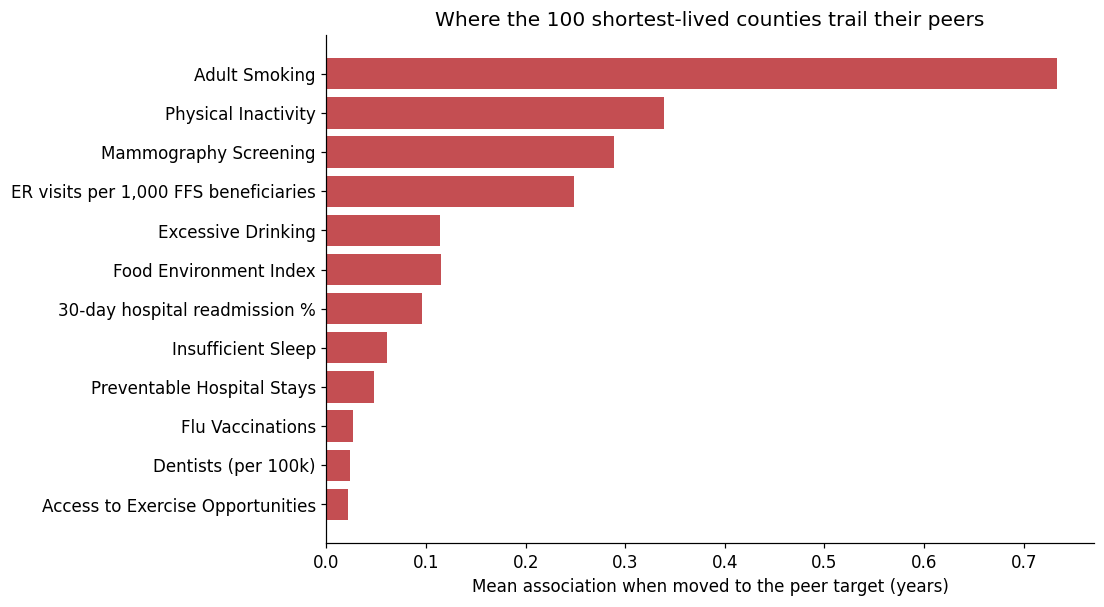

,counties,mean_years,total_years,% of the 100
label,,,,
Adult Smoking,95,0.734,69.693,95.0
Physical Inactivity,97,0.339,32.912,97.0
Mammography Screening,90,0.289,25.992,90.0
"ER visits per 1,000 FFS beneficiaries",93,0.249,23.149,93.0
Excessive Drinking,89,0.114,10.103,89.0
Food Environment Index,87,0.115,9.992,87.0
30-day hospital readmission %,93,0.095,8.880,93.0
Insufficient Sleep,89,0.060,5.383,89.0
Preventable Hospital Stays,91,0.048,4.370,91.0



Read as: among counties already similar on size, rurality and demographics,
those with better values on these factors have longer life expectancy at 50.


In [23]:
# Which factors matter most across struggling counties?
summary = (w.groupby("label")
             .agg(counties=("fips", "nunique"),
                  mean_years=("years_gained", "mean"),
                  total_years=("years_gained", "sum"))
             .sort_values("total_years", ascending=False))
summary["% of the 100"] = (100 * summary["counties"] / N_WORST).round(0)

top = summary.head(12)[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.index, top["mean_years"], color="#C44E52")
ax.set_xlabel("Mean association when moved to the peer target (years)")
ax.set_title(f"Where the {N_WORST} shortest-lived counties trail their peers")
save(fig, "28_worst_counties_factors")
plt.show()

display(summary.head(12).round(3))
print("\nRead as: among counties already similar on size, rurality and demographics,")
print("those with better values on these factors have longer life expectancy at 50.")

## 11. Exploratory: how does childhood disadvantage reach life expectancy at 50?

Childhood circumstance did not survive into the final feature set — it is too entangled with
adult poverty, education and smoking to carry an independent coefficient. That is a modelling
answer, not a substantive one. The substantive question is still open: **if children in
poverty tracks so strongly with how long 50-year-olds live, what is it travelling through?**

The hypothesis tested here is a chain: childhood disadvantage leaves a county with more
crime, crime drives grocery stores out, residents eat worse, obesity rises, and chronic
disease shortens life. Each link is plausible and each is measurable in this dataset.

The method is **attenuation**. Regress life expectancy on children in poverty alone, then
add the proposed intermediate conditions and see how much of the original coefficient
survives. Everything is standardised first, so coefficients read as *standard deviations of
life expectancy per standard deviation of the predictor*. If the coefficient collapses, the
association is shared with those conditions rather than independent of them.

**What this cannot do.** A chain model and a common-cause model predict identical
attenuation. If childhood poverty independently produces crime, poor food access, obesity
*and* short lives, the numbers below look exactly the same. These are also county averages,
not people. Read every result as *consistent with* the pathway, never as evidence for it.

In [24]:
from sklearn.linear_model import LinearRegression

START = "chr_children_in_poverty"
HOM = "chr_homicides"
MEDS = ["chr_motor_vehicle_crash_deaths", "chr_food_environment_index", "chr_adult_obesity"]

NEEDED = [START, HOM] + MEDS
missing = [c for c in NEEDED if c not in df.columns]
if missing:
    print("Not available in this dataset, section skipped:", missing)
else:
    # Homicide counts are suppressed in small counties, so requiring homicides costs
    # more than half the sample. Every model below uses the SAME counties - the ones
    # with complete data on all five variables - so no comparison is confounded by
    # which counties happen to be present.
    sub = df[NEEDED + [OUTCOME, "acs_total_pop"]].dropna()
    zz = sub[NEEDED + [OUTCOME]]
    zz = (zz - zz.mean()) / zz.std(ddof=0)
    yy = zz[OUTCOME].values
    fit = lambda cols: LinearRegression().fit(zz[cols], yy).coef_[0]

    print(f"{len(sub):,} of {len(df):,} counties have all five variables")
    print(f"median population {sub['acs_total_pop'].median():,.0f} "
          f"vs {df['acs_total_pop'].median():,.0f} nationally "
          f"-> this is a metro-weighted subsample, noted again at the end")

1,305 of 3,079 counties have all five variables
median population 83,172 vs 26,318 nationally -> this is a metro-weighted subsample, noted again at the end


### The variables, and how they move together

Spearman rather than Pearson, because several of these are rates with long right tails.

In [25]:
if not missing:
    CHAIN_LABELS = {START: "Children in poverty", HOM: "Homicides",
                    "chr_motor_vehicle_crash_deaths": "Motor vehicle deaths",
                    "chr_food_environment_index": "Food environment index",
                    "chr_adult_obesity": "Adult obesity", OUTCOME: "LE at 50"}
    cm = sub[NEEDED + [OUTCOME]].corr(method="spearman").round(2)
    cm.index = [CHAIN_LABELS[c] for c in cm.index]
    cm.columns = [CHAIN_LABELS[c] for c in cm.columns]
    display(cm)
    print("The food environment index is scored so that HIGHER = better access, which is")
    print("why it correlates negatively with poverty and obesity and positively with LE.")

,Children in poverty,Homicides,Motor vehicle deaths,Food environment index,Adult obesity,LE at 50
Children in poverty,1.00,0.75,0.68,-0.76,0.67,-0.71
Homicides,0.75,1.00,0.62,-0.59,0.59,-0.61
Motor vehicle deaths,0.68,0.62,1.00,-0.59,0.62,-0.71
Food environment index,-0.76,-0.59,-0.59,1.00,-0.61,0.67
Adult obesity,0.67,0.59,0.62,-0.61,1.00,-0.75
LE at 50,-0.71,-0.61,-0.71,0.67,-0.75,1.00


The food environment index is scored so that HIGHER = better access, which is
why it correlates negatively with poverty and obesity and positively with LE.


### Does the crime link do any work?

The first link in the chain is the one worth testing hardest, because it is the one most
likely to be wrong. Fit the model with and without homicides on the identical set of
counties. If crime is a real step, dropping it should leave more of the childhood-poverty
coefficient unexplained.

In [26]:
if not missing:
    base = fit([START])
    print(f"{'children in poverty alone':42} {base:+.3f}")
    print()
    att_hom = {}
    for lbl, cols in [("with homicides", [START, HOM] + MEDS),
                      ("without homicides", [START] + MEDS)]:
        c = fit(cols)
        att_hom[lbl] = 100 * (1 - abs(c) / abs(base))
        print(f"{lbl:42} {c:+.3f}   ({att_hom[lbl]:.0f}% attenuated)")
    print()
    gap = att_hom["with homicides"] - att_hom["without homicides"]
    print(f"Including homicides changes the attenuation by {gap:+.1f} percentage points.")
    if abs(gap) < 5:
        print("That is noise. Once a county's food environment, obesity rate and road")
        print("deaths are known, its homicide rate adds nothing about why childhood")
        print("disadvantage tracks with shorter life at 50 -> the crime step is NOT")
        print("supported as a distinct link in the chain.")
    else:
        print("That is large enough to take seriously: homicides carry something the other")
        print("mediators do not, which is what the crime link predicts.")

children in poverty alone                  -0.676

with homicides                             -0.137   (80% attenuated)
without homicides                          -0.124   (82% attenuated)

Including homicides changes the attenuation by -1.9 percentage points.
That is noise. Once a county's food environment, obesity rate and road
deaths are known, its homicide rate adds nothing about why childhood
disadvantage tracks with shorter life at 50 -> the crime step is NOT
supported as a distinct link in the chain.


### Which of the remaining conditions carries the pathway?

Drop one mediator at a time. The bigger the fall in attenuation, the more of the pathway
that condition carries that the others do not.

In [27]:
if not missing:
    rows = []
    full = fit([START] + MEDS)
    att = lambda c: 100 * (1 - abs(c) / abs(base))
    rows.append({"model": "all three mediators", "coef": full, "attenuation_pct": att(full),
                 "points_lost": 0.0})
    for drop in MEDS:
        c = fit([START] + [m for m in MEDS if m != drop])
        rows.append({"model": "without " + label(drop), "coef": c,
                     "attenuation_pct": att(c), "points_lost": att(full) - att(c)})
    decomp = pd.DataFrame(rows).round(3)
    display(decomp)
    uniq = decomp["points_lost"][1:].sum()
    print(f"points_lost is each mediator's UNIQUE contribution: what the full model loses")
    print(f"when that one is removed. The three sum to {uniq:.0f} points against a total")
    print(f"attenuation of {att(full):.0f}. The shortfall is the overlap between them - they")
    print("are largely three measurements of one shared condition, which is what sits on a")
    print("common pathway rather than on three independent ones.")

,model,coef,attenuation_pct,points_lost
0,all three mediators,-0.124,81.655,0.000
1,without Motor Vehicle Crash Deaths,-0.212,68.566,13.088
2,without Food Environment Index,-0.205,69.613,12.042
3,without Adult Obesity,-0.300,55.594,26.061


points_lost is each mediator's UNIQUE contribution: what the full model loses
when that one is removed. The three sum to 51 points against a total
attenuation of 82. The shortfall is the overlap between them - they
are largely three measurements of one shared condition, which is what sits on a
common pathway rather than on three independent ones.


### Is obesity just food access arriving late?

Food access sits upstream of obesity in the hypothesis. If food environment mattered *only*
by making people heavier, then adding it to a model that already contains obesity should
change nothing. Nesting the two settles it.

In [28]:
if not missing:
    print(f"food environment <-> obesity:  Spearman r = "
          f"{sub['chr_food_environment_index'].corr(sub['chr_adult_obesity'], method='spearman'):+.2f}")
    print()
    for cols in [[START],
                 [START, "chr_food_environment_index"],
                 [START, "chr_adult_obesity"],
                 [START, "chr_food_environment_index", "chr_adult_obesity"]]:
        c = fit(cols)
        nm = " + ".join(label(x) for x in cols[1:]) or "nothing added"
        print(f"{nm:52} {c:+.3f}   ({att(c):.0f}%)")

food environment <-> obesity:  Spearman r = -0.61

nothing added                                        -0.676   (0%)
Food Environment Index                               -0.469   (31%)
Adult Obesity                                        -0.307   (55%)
Food Environment Index + Adult Obesity               -0.212   (69%)


Saved C:\Users\14438\data\processed\figures\31_childhood_pathway_attenuation.png


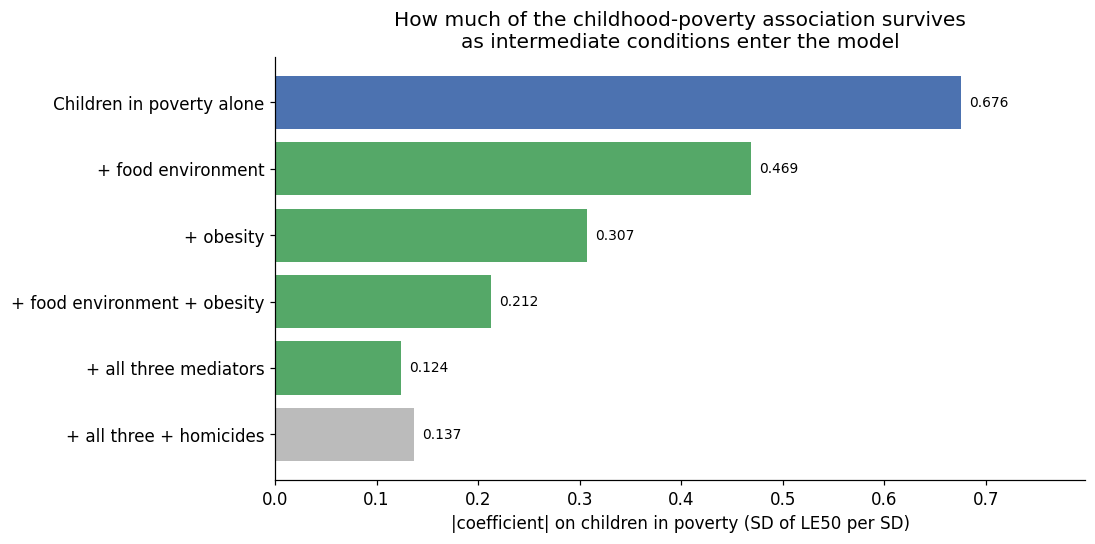

In [29]:
if not missing:
    specs = [("Children in poverty alone", [START]),
             ("+ food environment", [START, "chr_food_environment_index"]),
             ("+ obesity", [START, "chr_adult_obesity"]),
             ("+ food environment + obesity",
              [START, "chr_food_environment_index", "chr_adult_obesity"]),
             ("+ all three mediators", [START] + MEDS),
             ("+ all three + homicides", [START, HOM] + MEDS)]
    vals = [abs(fit(c)) for _, c in specs]
    names = [n for n, _ in specs]

    fig, ax = plt.subplots(figsize=(9.5, 5))
    cols_bar = ["#4C72B0"] + ["#55A868"] * 4 + ["#BBBBBB"]
    ax.barh(names[::-1], vals[::-1], color=cols_bar[::-1])
    for k, v in enumerate(vals[::-1]):
        ax.text(v + 0.008, k, f"{v:.3f}", va="center", fontsize=9)
    ax.set_xlabel("|coefficient| on children in poverty (SD of LE50 per SD)")
    ax.set_title("How much of the childhood-poverty association survives\n"
                 "as intermediate conditions enter the model")
    ax.set_xlim(0, max(vals) * 1.18)
    save(fig, "31_childhood_pathway_attenuation")
    plt.show()

### How much of this is the metro-weighted sample?

Everything above is restricted to counties that report homicides, which skews large. The
same three mediators can be tested on every county that has them, which is twice as many
places and much more rural. If the attenuation differs, the pathway is not working the same
way everywhere.

In [30]:
if not missing:
    wide = df[[START] + MEDS + [OUTCOME, "acs_total_pop"]].dropna()
    zw = wide[[START] + MEDS + [OUTCOME]]
    zw = (zw - zw.mean()) / zw.std(ddof=0)
    yw = zw[OUTCOME].values
    fw = lambda cols: LinearRegression().fit(zw[cols], yw).coef_[0]
    bw, mw = fw([START]), fw([START] + MEDS)

    comp = pd.DataFrame([
        {"sample": "counties reporting homicides", "counties": len(sub),
         "median_pop": sub["acs_total_pop"].median(), "alone": base,
         "with_mediators": full, "attenuation_pct": att(full)},
        {"sample": "all counties with the three mediators", "counties": len(wide),
         "median_pop": wide["acs_total_pop"].median(), "alone": bw,
         "with_mediators": mw, "attenuation_pct": 100 * (1 - abs(mw) / abs(bw))},
    ]).set_index("sample").round(3)
    display(comp)
    d = comp["attenuation_pct"].iloc[0] - comp["attenuation_pct"].iloc[1]
    print(f"Same three mediators, different counties, {abs(d):.0f} percentage points apart.")
    if d > 5:
        print("The pathway accounts for more in larger counties. In the wider, more rural")
        print("sample a sizeable share of the association survives, so something other")
        print("than food access, obesity and road deaths carries it in small places.")
    elif d < -5:
        print("The pathway accounts for MORE in the wider, more rural sample - the")
        print("opposite of what the metro-weighted subsample suggested.")
    else:
        print("Close enough to treat as the same: the pathway behaves similarly in both,")
        print("so the earlier metro-weighted result was not a sample artefact.")

,counties,median_pop,alone,with_mediators,attenuation_pct
sample,,,,,
counties reporting homicides,1305,83172.0,-0.676,-0.124,81.655
all counties with the three mediators,2648,33626.5,-0.659,-0.264,59.969


Same three mediators, different counties, 22 percentage points apart.
The pathway accounts for more in larger counties. In the wider, more rural
sample a sizeable share of the association survives, so something other
than food access, obesity and road deaths carries it in small places.


### What this section found

Key findings

Main association: The association between childhood poverty and life expectancy at age 50 is reduced by roughly 80% after accounting for adult obesity, food environment and motor vehicle deaths.

Largest contribution: Adult obesity accounts for the largest unique share of the explained association.
Crime: County homicide rates add no explanatory power when tested on the same sample. The results do not support an additional pathway through crime, although this does not rule out a broader relationship between crime and disadvantage.

Motor vehicle deaths: These contribute about as much as food environment, pointing to a separate pathway potentially involving road exposure, travel distances, emergency response times and drinking patterns.

Food environment and obesity: Both contribute explanatory power when the other is included in the model. This suggests that the association between food environment and life expectancy is not fully captured by obesity alone.
Differences by county size: The model accounts for more of the association in larger counties. A substantial share remains unexplained in smaller, more rural counties.

Interpretation: These results are consistent with several overlapping pathways between childhood poverty and life expectancy, but they do not establish causal mediation. The differences between county groups also suggest that additional factors may be important in rural areas.

## 12. Export for the website

Three tidy files the dashboard can read directly, with no model at run time.

In [31]:
# 1. Predictions and residuals
pred_out = df[["fips", "place", "state", "county_name", OUTCOME, "le50_male", "le50_female",
               "pred", "residual", "acs_total_pop", "rucc"]].copy()
pred_out["national_rank"] = df[OUTCOME].rank(ascending=False).astype(int)
pred_out["peer_mean"] = [peers(i)[OUTCOME].mean() for i in df.index]
pred_out["peer_best"] = [peers(i)[OUTCOME].max() for i in df.index]
pred_out["peer_fips"] = [";".join(df.fips.iloc[peer_idx[i]]) for i in df.index]
pred_out.round(3).to_csv(DATA_DIR / "county_predictions.csv", index=False)

# 2. Per-county SHAP values
if HAS_SHAP:
    sh_out = shap_df.copy()
    sh_out.insert(0, "fips", df["fips"])
    sh_out.round(4).to_csv(DATA_DIR / "county_shap.csv", index=False)

# 3. Scenarios for every county (a few minutes)
rows = []
for i in df.index:
    s, base_pred, combined, n_gaps = scenarios(i, top=5)
    for r in s.itertuples():
        rows.append({"fips": df.fips[i], "feature": r.feature, "label": r.label,
                     "current": r._3, "peer_target": r.to,
                     "years_gained": r.years_gained,
                     "combined_all_gaps": combined, "n_gaps": n_gaps})
    if i % 500 == 0:
        print(f"  {i}/{len(df)}")
scen = pd.DataFrame(rows)
scen.round(3).to_csv(DATA_DIR / "county_scenarios.csv", index=False)

print(f"\nWrote {len(pred_out):,} predictions"
      + (f", {len(shap_df):,} SHAP rows" if HAS_SHAP else "")
      + f", {len(scen):,} scenario rows")
print(f"Combined-scenario gains: median {scen.groupby('fips').combined_all_gaps.first().median():.2f} "
      f"years, 90th pct {scen.groupby('fips').combined_all_gaps.first().quantile(.9):.2f}")

  0/3079
  500/3079
  1000/3079
  1500/3079
  2000/3079
  2500/3079
  3000/3079

Wrote 3,079 predictions, 3,079 SHAP rows, 15,316 scenario rows
Combined-scenario gains: median 0.42 years, 90th pct 1.39


## 13. Limitations to state in the write-up

1. **Ecological and associational.** Counties are the unit, not people. A county-level
   association need not hold for individuals (the ecological fallacy), and nothing here
   identifies a causal effect.
2. **Scenario numbers are comparisons, not forecasts.** "+1.1 years" means similar counties
   with that value have higher life expectancy. Say it that way.
3. **Correlated predictors share credit.** Smoking, poverty and education move together, so
   any one feature's attributed effect absorbs some of the others.
4. **Mortality responds slowly.** Life expectancy at 50 reflects decades of accumulated
   exposure; a change today would take years to register.
5. **Selection and migration.** Resort and retirement counties gain healthy in-movers;
   prison and university counties have unusual populations. Migration features partly
   capture this, but not completely.
6. **Period measure, pre-COVID.** 2019 death rates, not a forecast of anyone's lifespan.
7. **Suppression.** Sparse features are missing mainly in small rural counties, so
   imputation nudges those counties toward the median.